# 03 — Baselines & logistic regression

Goal: the first real model, and the **evaluation harness** every later model reuses.
Read [`docs/02_logistic_regression.md`](../docs/02_logistic_regression.md) alongside this.

1. Split the feature table by date into train / validation
2. Two baselines that need no machine learning: **naive** (better rank wins) and the **Elo formula**
3. Logistic regression: a scikit-learn **pipeline**, tuning `C` on validation
4. Compare, read the coefficients, and check the probabilities are honest

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from data_loading import load_matches
from evaluate import (TEST_START, TRAIN_START, VAL_START, accuracy_gap, elo_baseline_predict,
                      evaluate_predictions, naive_baseline_predict, split, summarize_results)
from features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, build_feature_table

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

ft = build_feature_table(load_matches())
train, val = split(ft)
print(f"train: {TRAIN_START} → {VAL_START}  {len(train):,} matches")
print(f"val:   {VAL_START} → {TEST_START}  {len(val):,} matches")

train: 2012-01-01 → 2025-04-01  36,193 matches
val:   2025-04-01 → 2026-01-01  1,872 matches


## 1. The split

- **Train** — the model learns from these. Starts in 2012: 2010–11 only warm up Elo (notebook 02, section 7).
- **Validation** — Apr–Dec 2025. Used to *compare* models and *choose settings*. The model never trains on it.
- **Test** — 2026, held back until Phase 6, used once per model.

Why by **date** and not a random shuffle? Because that's how the model is used: trained on the past, predicting the future.
A random split would let it train on December 2025 and "predict" April 2025.

`split()` also drops walkovers (never played) and retirements (partly an injury, not tennis) from both — they still fed Elo,
form and H2H when the feature table was built.

## 2. Metrics

| Metric | Question it answers | Better | Coin flip (always 0.5) |
|---|---|---|---|
| **Accuracy** | Did it pick the right player? | higher | 50% |
| **Log-loss** | Were its probabilities honest? Punishes confident mistakes hard | lower | 0.693 |
| **Brier** | Same idea, gentler: average of (p − outcome)² | lower | 0.25 |

In [2]:
# Log-loss for one match is -ln(probability given to what actually happened)
for p in [0.5, 0.7, 0.9, 0.99]:
    print(f"said {p:.2f} for p1:  if p1 won {-np.log(p):.2f}   if p1 lost {-np.log(1 - p):.2f}")

said 0.50 for p1:  if p1 won 0.69   if p1 lost 0.69
said 0.70 for p1:  if p1 won 0.36   if p1 lost 1.20
said 0.90 for p1:  if p1 won 0.11   if p1 lost 2.30
said 0.99 for p1:  if p1 won 0.01   if p1 lost 4.61


## 3. Baselines

Any model has to beat these to be worth anything.

- **Naive:** the better-ranked player wins with the probability seen in training (~66%). It needs a probability, not just a pick,
  so log-loss is finite — a 100% guess that turns out wrong costs infinity.
- **Elo formula:** `1 / (1 + 10^(−elo_diff/400))`, straight from [docs/01_elo.md](../docs/01_elo.md). No training at all.

In [3]:
p_naive = naive_baseline_predict(train, val)
p_elo = elo_baseline_predict(val)
results = {
    "naive (rank)": evaluate_predictions(val.p1_won, p_naive),
    "Elo formula": evaluate_predictions(val.p1_won, p_elo),
}
summarize_results(results)

,accuracy,log_loss,brier
naive (rank),0.6538,0.6446,0.2261
Elo formula,0.6464,0.6287,0.2194


## 4. Logistic regression

A scikit-learn **pipeline** chains preprocessing and the model, so exactly the same steps run when training and when predicting:

1. `SimpleImputer(fill_value=0)` — blanks (e.g. `form_diff` for a debut) become 0, i.e. "no difference"
2. `StandardScaler()` — each feature → (value − mean) / standard deviation, learned from **train only**
3. `LogisticRegression(fit_intercept=False)` — no intercept, so swapping the players exactly flips the prediction (section 9 shows why)

We only feed it the six difference features. Section 9 shows what happens with the surface/round/level columns too.

### Tuning C on validation

In [4]:
def make_logreg(C):
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value=0),
        StandardScaler(),
        LogisticRegression(C=C, fit_intercept=False),
    )

X_train, y_train = train[NUMERIC_FEATURES], train.p1_won
X_val, y_val = val[NUMERIC_FEATURES], val.p1_won

tuning = {f"C={C}": evaluate_predictions(y_val, make_logreg(C).fit(X_train, y_train).predict_proba(X_val)[:, 1])
          for C in [0.001, 0.01, 0.1, 1]}
summarize_results(tuning)

,accuracy,log_loss,brier
C=0.001,0.6538,0.6098,0.2120
C=0.01,0.6538,0.6118,0.2127
C=0.1,0.6544,0.6122,0.2129
C=1,0.6533,0.6123,0.2129


`C` is the inverse of regularization strength: smaller C pulls weights harder towards 0. The differences are tiny — 36k matches and
six features leave little room to overfit — and C = 0.001 is (just) best on log-loss, so we keep it.

`predict_proba(X)[:, 1]` returns P(class 1) = P(p1 wins) for each row.

In [5]:
logreg = make_logreg(C=0.001).fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_val)[:, 1]
results["logistic regression"] = evaluate_predictions(y_val, p_logreg)
summarize_results(results)

,accuracy,log_loss,brier
naive (rank),0.6538,0.6446,0.2261
Elo formula,0.6464,0.6287,0.2194
logistic regression,0.6538,0.6098,0.2120


## 5. Did it beat the baseline?

In [6]:
for name, p in [("naive", p_naive), ("Elo formula", p_elo)]:
    gap, margin = accuracy_gap(y_val, p_logreg, p)
    print(f"logreg vs {name:12s} accuracy {gap:+.2%} ± {margin:.2%}")

logreg vs naive        accuracy +0.00% ± 1.66%
logreg vs Elo formula  accuracy +0.75% ± 1.42%


- **Log-loss: yes, clearly** (0.645 → 0.610). Its probabilities are much better than "66% for the favourite every time".
- **Accuracy: a tie.** The gap is 0 ± ~1.7 points. With ~1,900 validation matches, any accuracy gap under ~2 points is noise.

Why the tie? Look at the matches where the two **disagree**:

In [7]:
disagree = (p_logreg > 0.5) != (p_naive > 0.5)
logreg_right = (p_logreg[disagree] > 0.5) == (y_val[disagree] == 1)
print(f"disagree on {disagree.sum()} of {len(val)} matches ({disagree.mean():.0%})")
print(f"logreg right on {logreg_right.mean():.0%} of those")
val[disagree][["tourney_name", "round", "p1_name", "p1_rank", "p2_name", "p2_rank", "p1_won"]].assign(
    p_logreg=p_logreg[disagree].round(2)).head(8)

disagree on 250 of 1872 matches (13%)
logreg right on 50% of those


,tourney_name,round,p1_name,p1_rank,p2_name,p2_rank,p1_won,p_logreg
43576,Monte Carlo Masters,R64,Jiri Lehecka,28.0,Sebastian Korda,24.0,1,0.53
43598,Monte Carlo Masters,R16,Daniil Medvedev,11.0,Alex De Minaur,10.0,0,0.55
43601,Monte Carlo Masters,R16,Lorenzo Musetti,16.0,Matteo Berrettini,34.0,1,0.49
43611,Munich,R32,Miomir Kecmanovic,48.0,Marcos Giron,45.0,1,0.55
43626,Munich,R16,Luciano Darderi,47.0,Miomir Kecmanovic,48.0,1,0.49
43637,Munich,SF,Ben Shelton,15.0,Francisco Cerundolo,22.0,1,0.47
43654,Barcelona,R32,Laslo Djere,80.0,Arthur Rinderknech,75.0,1,0.61
43675,Madrid Masters,R128,Hamad Medjedovic,61.0,Tomas Martin Etcheverry,51.0,0,0.51


Most of the time both pick the favourite. When logreg goes against the ranking (usually because Elo or surface Elo disagrees with it),
those are close matches — and it's right about half the time. Its value is in **how confident** it is, not **who** it picks.

## 6. Reading the coefficients

In [8]:
coefs = pd.DataFrame({
    "weight": logreg[-1].coef_[0],
    "odds × per 1 SD": np.exp(logreg[-1].coef_[0]),
    "1 SD is": logreg[1].scale_,   # StandardScaler learned these from train
}, index=NUMERIC_FEATURES).sort_values("weight", key=abs, ascending=False)
coefs.round(3)

,weight,odds × per 1 SD,1 SD is
log_rank_diff,-0.371,0.690,1.495
surface_elo_diff,0.325,1.384,213.293
elo_diff,0.258,1.294,211.689
h2h_diff,0.069,1.071,1.494
rank_points_diff,0.051,1.052,2454.626
form_diff,0.039,1.040,0.240


Each weight = change in **log-odds** of p1 winning per one-standard-deviation increase in that feature; `e^weight` is the
**odds multiplier**. Because all features are standardized, the weights are directly comparable.

- `log_rank_diff` is negative because positive means p1 is ranked **worse**.
- Surface Elo outweighs overall Elo; form and H2H add little once rank and Elo are known.

### Correlated features: read them as a group

In [9]:
print(ft[NUMERIC_FEATURES].corr().round(2).loc[["log_rank_diff", "rank_points_diff", "elo_diff"]])
weak_reg = make_logreg(C=1).fit(X_train, y_train)
pd.DataFrame({"C=0.001": logreg[-1].coef_[0], "C=1": weak_reg[-1].coef_[0]}, index=NUMERIC_FEATURES).round(3)

                  log_rank_diff  rank_points_diff  elo_diff  surface_elo_diff  \
log_rank_diff              1.00             -0.83     -0.82             -0.72   
rank_points_diff          -0.83              1.00      0.75              0.68   
elo_diff                  -0.82              0.75      1.00              0.87   

                  form_diff  h2h_diff  
log_rank_diff         -0.49     -0.28  
rank_points_diff       0.43      0.39  
elo_diff               0.71      0.31  


,C=0.001,C=1
log_rank_diff,-0.371,-0.534
rank_points_diff,0.051,-0.117
elo_diff,0.258,0.244
surface_elo_diff,0.325,0.401
form_diff,0.039,0.006
h2h_diff,0.069,0.084


`rank_points_diff` flips sign between the two settings even though the predictions barely change. It's 83% correlated with
`log_rank_diff` — they carry nearly the same information, and the model splits the credit between them somewhat arbitrarily.
**Never read one coefficient of a correlated group in isolation.**

## 7. Worked example: 2025 US Open final

The same arithmetic the model does, by hand (also in the doc):

In [10]:
match = val[(val.tourney_name == "Us Open") & (val["round"] == "F")]
x = match[NUMERIC_FEATURES].fillna(0).iloc[0]
scaled = (x - logreg[1].mean_) / logreg[1].scale_
contrib = scaled * logreg[-1].coef_[0]
z = contrib.sum()
print(f"p1 = {match.p1_name.iloc[0]}, p2 = {match.p2_name.iloc[0]}, p1 won = {match.p1_won.iloc[0]}")
print(f"z = {z:.3f} → p = 1/(1+e^-z) = {1 / (1 + np.exp(-z)):.3f}   (model says {logreg.predict_proba(match[NUMERIC_FEATURES])[0, 1]:.3f})")
pd.DataFrame({"raw": x, "standardized": scaled, "weight": logreg[-1].coef_[0], "contribution": contrib}).round(3)

p1 = Jannik Sinner, p2 = Carlos Alcaraz, p1 won = 0
z = 0.293 → p = 1/(1+e^-z) = 0.573   (model says 0.573)


,raw,standardized,weight,contribution
log_rank_diff,-0.693,-0.466,-0.371,0.173
rank_points_diff,1890.000,0.770,0.051,0.039
elo_diff,29.679,0.141,0.258,0.037
surface_elo_diff,161.572,0.757,0.325,0.246
form_diff,-0.100,-0.415,0.039,-0.016
h2h_diff,-4.000,-2.683,0.069,-0.185


## 8. Are the probabilities honest? (calibration)

If the model says 70% for a group of matches, about 70% of them should go that way. Group validation predictions into bins
and compare the average prediction with how often p1 actually won. A perfectly calibrated model sits on the diagonal.

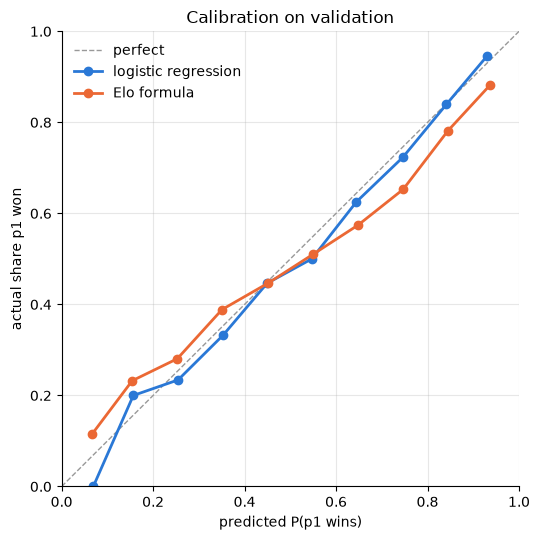

In [11]:
def calibration(p, y, bins=10):
    b = pd.cut(p, np.linspace(0, 1, bins + 1))
    g = pd.DataFrame({"p": p, "y": y.to_numpy(), "bin": b}).groupby("bin", observed=True)
    return g.p.mean(), g.y.mean(), g.size()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="0.6", linestyle="--", linewidth=1, label="perfect")
for (name, p), color in zip([("logistic regression", p_logreg), ("Elo formula", p_elo)], COLORS):
    pred, actual, n = calibration(p, y_val)
    ax.plot(pred, actual, marker="o", markersize=6, linewidth=2, color=color, label=name)
ax.set(xlabel="predicted P(p1 wins)", ylabel="actual share p1 won", xlim=(0, 1), ylim=(0, 1),
       title="Calibration on validation")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

Logistic regression tracks the diagonal; the Elo formula is **over-confident** at the extremes (its points bend towards the middle:
when it says 85%, the favourite wins less often than that). Logistic regression learned its own scale for Elo, which is a big part
of why its log-loss is lower. Bins at the ends hold fewer matches, so they wobble more.

## 9. Why no surface / round / level columns?

Player 1 is picked by coin flip. A column like `surface` is the **same** whichever player is p1, so on its own it can't say anything
about *which* player wins — any weight it gets is fitting noise. Let's prove it by adding them (one-hot encoded) plus an intercept:

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

with_context = make_pipeline(
    ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ]),
    LogisticRegression(C=1, max_iter=1000),
).fit(train[NUMERIC_FEATURES + CATEGORICAL_FEATURES], y_train)

w = pd.Series(with_context[-1].coef_[0], index=with_context[0].get_feature_names_out())
print("largest context weights:")
print(w[w.index.str.startswith("cat__")].sort_values(key=abs, ascending=False).head(4).round(3))

largest context weights:
cat__tourney_level_O    0.296
cat__surface_Carpet    -0.241
cat__surface_nan        0.184
cat__tourney_level_D   -0.106
dtype: float64


In [13]:
# Symmetry test: swap p1 and p2 (negate every difference). A fair model's two answers must add up to 1.
swapped = val.copy()
swapped[NUMERIC_FEATURES] = -swapped[NUMERIC_FEATURES]
cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES
for name, model, X, Xs in [("diffs only, no intercept", logreg, X_val, swapped[NUMERIC_FEATURES]),
                           ("with context + intercept", with_context, val[cols], swapped[cols])]:
    total = model.predict_proba(X)[:, 1] + model.predict_proba(Xs)[:, 1]
    print(f"{name:26s} p + p_swapped: min {total.min():.3f}, max {total.max():.3f}")
evaluate_predictions(y_val, with_context.predict_proba(val[cols])[:, 1])

diffs only, no intercept   p + p_swapped: min 1.000, max 1.000
with context + intercept   p + p_swapped: min 0.932, max 1.016


{'accuracy': 0.6501068376068376,
 'log_loss': 0.6123309584795594,
 'brier': 0.21295080733479088}

With context columns the model claims things like "at the Olympics, player 1 is more likely to win" — but player 1 is a coin flip,
so that's noise, and its answer changes depending on which way round you list the players. It doesn't help validation either.

Context *can* matter through **interactions** — e.g. "the ranking gap matters more in best-of-5". A linear model only gets those if you
build the product columns by hand. Decision trees (Phase 4) find interactions on their own, which is one reason to try them.

## 10. Check your understanding

1. Why split by date instead of randomly?
2. A model says 0.95 for a match the favourite loses. Why does log-loss punish that so much more than accuracy does?
3. What does `StandardScaler` do, and why does it matter for reading coefficients?
4. `elo_diff` has weight 0.26. In words, what does that mean?
5. Logistic regression and the naive rule have the same accuracy. In what sense is logistic regression still better?
6. Why does a `surface` column on its own get only noise weights here?
7. `rank_points_diff` changes sign between C = 0.001 and C = 1. Should you conclude ranking points don't matter?

<details><summary>1. Date split</summary>

The model will be used to predict the future from the past. A random split would let it learn from matches *after* the ones it's
tested on (e.g. a player's later rise), making validation look better than real use.
</details>

<details><summary>2. Confident mistakes</summary>

Accuracy counts it as one wrong pick, same as a 51% miss. Log-loss charges −ln(0.05) = 3.0, about 4× a coin-flip's 0.69,
because the model claimed to be nearly certain. That's what pushes models towards honest probabilities.
</details>

<details><summary>3. StandardScaler</summary>

It turns each feature into "how many standard deviations from its average". Then every coefficient is "effect of a one-SD change",
so they're comparable across features measured in Elo points, ranks or win rates. It also makes regularization treat them equally.
</details>

<details><summary>4. elo_diff weight 0.26</summary>

Holding the other features fixed, being one standard deviation (~212 Elo points) higher-rated than your opponent multiplies your
odds of winning by e^0.26 ≈ 1.3.
</details>

<details><summary>5. Same accuracy, still better</summary>

Its probabilities are far more informative and honest (log-loss 0.610 vs 0.645): it tells a 97% mismatch apart from a 52% toss-up,
where the naive rule says 66% for both. For anything that uses the probability — betting, simulating a draw — that's what counts.
</details>

<details><summary>6. surface alone</summary>

Player 1 is assigned by coin flip, and the surface is the same whichever player is p1, so surface can't tell you *which* player wins.
It could only matter combined with a difference feature (an interaction).
</details>

<details><summary>7. rank_points_diff sign flip</summary>

No. It's 83% correlated with `log_rank_diff`, so the model can shift weight between them with almost no change in predictions.
Judge correlated features together — e.g. by dropping both and seeing how much worse the model gets.
</details>